# RQ1 presentation figures: species-level performance across model configurations

Three slide figures (16:9) for the RQ1 section of the talk:

1. **Finding fish vs naming the species**: any-fish AP50 vs species-level macro mAP50 for each baseline model
2. **Model size**: macro mAP50 against computational cost (diminishing returns, e.g. Detection M 0.302 vs L 0.306)
3. **Detection vs segmentation**: macro mAP50 at each model size

**Data source.** All values are copied from the existing analysis of the pooled out-of-fold test predictions
(120 runs, 5 folds, 2 seeds averaged), so this notebook needs no data files and runs anywhere.
Baseline models only. Detection is scored with box IoU and segmentation with mask IoU (as in the report).
Macro mAP50 = mean AP50 over the 20 classes with ≥20 instances; any-fish AP50 = class-agnostic detection of all fish.
Error bars are 95% paired block-bootstrap CIs (2,000 resamples of the 49 temporal blocks).

Set `THEME` to `'light'` or `'dark'` to match your slides. Figures are saved as PNG (and PDF) next to the notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

THEME = 'light'          # 'light' or 'dark'
SAVE = True              # write PNG + PDF files
DPI = 150

## Data (baseline models)

In [2]:
MODELS = ['detect_s', 'detect_m', 'detect_l', 'segment_s', 'segment_m', 'segment_l']
LABEL = {'detect_s': 'Detection S', 'detect_m': 'Detection M', 'detect_l': 'Detection L',
         'segment_s': 'Segmentation S', 'segment_m': 'Segmentation M', 'segment_l': 'Segmentation L'}

# [estimate, 95% CI low, 95% CI high]
MACRO = {   # species-level macro mAP50 (20 classes with >= 20 instances)
    'detect_s': [0.262, 0.241, 0.308], 'detect_m': [0.302, 0.275, 0.358], 'detect_l': [0.306, 0.278, 0.355],
    'segment_s': [0.255, 0.227, 0.303], 'segment_m': [0.280, 0.254, 0.328], 'segment_l': [0.302, 0.271, 0.354]}
ANYFISH = { # class-agnostic fish detection AP50
    'detect_s': [0.670, 0.613, 0.721], 'detect_m': [0.694, 0.637, 0.744], 'detect_l': [0.681, 0.621, 0.736],
    'segment_s': [0.676, 0.618, 0.727], 'segment_m': [0.689, 0.629, 0.741], 'segment_l': [0.680, 0.622, 0.732]}
GFLOPS = {'detect_s': 95, 'detect_m': 305, 'detect_l': 380, 'segment_s': 153, 'segment_m': 533, 'segment_l': 609}  # at 1280 px
PARAMS_M = {'detect_s': 10.0, 'detect_m': 21.9, 'detect_l': 26.3, 'segment_s': 11.5, 'segment_m': 27.1, 'segment_l': 31.5}

# paired differences in macro mAP50, [estimate, CI low, CI high] (unadjusted)
SIZE_STEP = {('detect', 's', 'm'): [0.039, 0.019, 0.064], ('detect', 'm', 'l'): [0.004, -0.019, 0.020],
             ('segment', 's', 'm'): [0.025, 0.008, 0.043], ('segment', 'm', 'l'): [0.022, 0.002, 0.041]}
SEG_MINUS_DET = {'s': [-0.008, -0.033, 0.009], 'm': [-0.021, -0.049, -0.007], 'l': [-0.003, -0.023, 0.014]}

## Style

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', grid='#e1e0d9', axis='#898781',
                  blue='#2a78d6', orange='#eb6834', base='#a3a29b'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', grid='#26354b', axis='#6d7a8e',
                  blue='#4a90e8', orange='#e2683a', base='#7f8a9b'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 16, 'text.color': T['ink'],
                     'axes.labelcolor': T['ink2'], 'axes.edgecolor': T['axis'], 'xtick.color': T['ink2'],
                     'ytick.color': T['ink2'], 'axes.facecolor': T['bg'], 'figure.facecolor': T['bg'],
                     'savefig.facecolor': T['bg'], 'axes.titlesize': 20, 'axes.titleweight': 'bold',
                     'axes.titlecolor': T['ink'], 'axes.titlelocation': 'left', 'axes.titlepad': 14,
                     'legend.frameon': False, 'legend.fontsize': 15})
FS = (13.33, 7.5)   # 16:9 slide

def clean(ax, grid='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    if grid: ax.grid(axis=grid, color=T['grid'], lw=1); ax.set_axisbelow(True)
    ax.tick_params(length=0)

def save(fig, name):
    if SAVE:
        for ext in ('png', 'pdf'): fig.savefig(f'{name}_{THEME}.{ext}', dpi=DPI)
    plt.show()

def err(d, k):  # matplotlib yerr from [est, lo, hi]
    e, lo, hi = d[k]; return [[e - lo], [hi - e]]

## Figure 1: Finding fish vs identifying the species
*"Class-agnostic fish detection ... 0.67 to 0.69. However, species-level mean average precision was considerably lower, 0.25 to 0.31."*

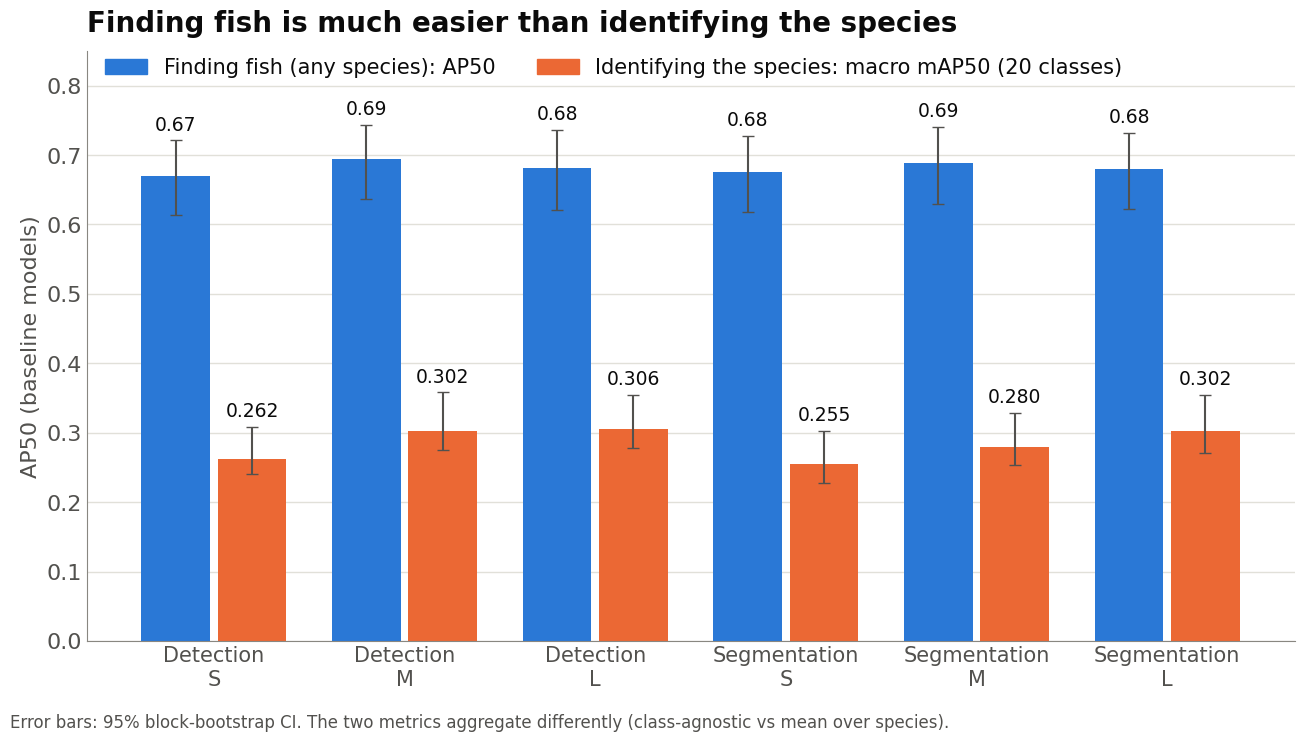

In [ ]:
fig, ax = plt.subplots(figsize=FS)
x = np.arange(len(MODELS)); w = 0.36
for i, m in enumerate(MODELS):
    for dx, d, col in [(-w / 2 - 0.02, ANYFISH, T['blue']), (w / 2 + 0.02, MACRO, T['orange'])]:
        ax.bar(x[i] + dx, d[m][0], w, color=col)
        ax.errorbar(x[i] + dx, d[m][0], yerr=err(d, m), fmt='none', ecolor=T['ink2'], elinewidth=1.5, capsize=4)
        ax.text(x[i] + dx, d[m][2] + 0.015, f'{d[m][0]:.3f}' if d is MACRO else f'{d[m][0]:.2f}',
                ha='center', fontsize=13.5, color=T['ink'])
ax.set_xticks(x); ax.set_xticklabels([LABEL[m].replace(' ', '\n', 1) for m in MODELS], fontsize=15)
ax.set_ylim(0, 0.85); ax.set_ylabel('AP50 (baseline models)'); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=T['blue']), plt.Rectangle((0, 0), 1, 1, color=T['orange'])],
          labels=['Finding fish (any species): AP50', 'Identifying species: macro mAP50'],
          loc='upper left', ncol=2, bbox_to_anchor=(0, 1.02))
ax.set_title('Finding fish is much easier than identifying the species')
fig.text(0.01, 0.01, 'Error bars: 95% block-bootstrap CI.', fontsize=12, color=T['ink2'])
fig.tight_layout(rect=(0, 0.03, 1, 1)); save(fig, 'rq1_fig1_detection_vs_species')

## Figure 2: Bigger models give diminishing returns
*"The medium detection model achieved a macro mAP50 of 0.302, compared with 0.306 for the large model."*

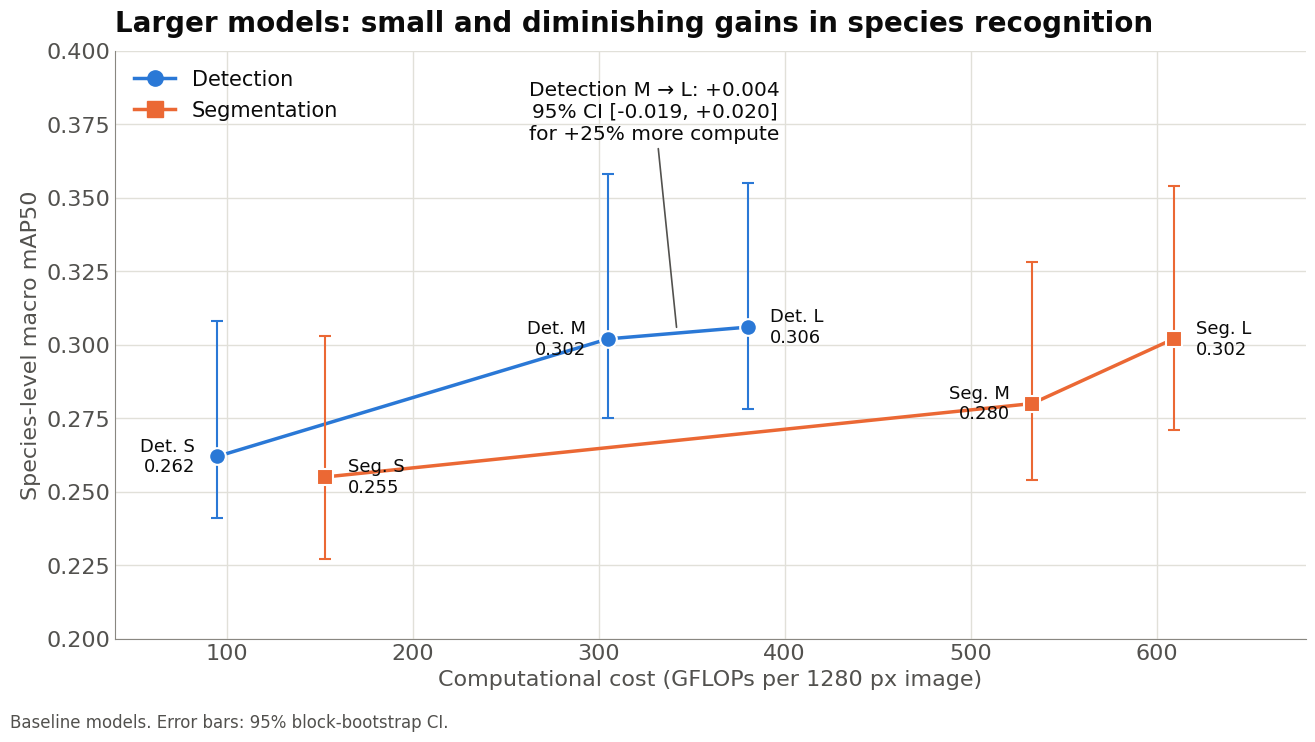

In [5]:
fig, ax = plt.subplots(figsize=FS)
for task, col, mk, name in [('detect', T['blue'], 'o', 'Detection'), ('segment', T['orange'], 's', 'Segmentation')]:
    ms = [f'{task}_{s}' for s in 'sml']
    gx = [GFLOPS[m] for m in ms]; gy = [MACRO[m][0] for m in ms]
    ax.plot(gx, gy, color=col, lw=2.5, zorder=2)
    for m, s in zip(ms, 'SML'):
        e, lo, hi = MACRO[m]
        ax.errorbar(GFLOPS[m], e, yerr=[[e - lo], [hi - e]], fmt=mk, ms=12, color=col, ecolor=col,
                    elinewidth=1.5, capsize=4, mec=T['bg'], mew=1.5, zorder=3)
        side = {'detect_s': -1, 'detect_m': -1, 'detect_l': 1, 'segment_s': 1, 'segment_m': -1, 'segment_l': 1}[m]
        ax.text(GFLOPS[m] + side * 12, e, f'{name[:3]}. {s}\n{e:.3f}', ha='left' if side > 0 else 'right',
                va='center', fontsize=13, color=T['ink'])
# highlight Detection M -> L
d = SIZE_STEP[('detect', 'm', 'l')]
ax.annotate(f'Detection M → L: {d[0]:+.3f}\n95% CI [{d[1]:+.3f}, {d[2]:+.3f}]\nfor +25% more compute',
            xy=(342, 0.305), xytext=(330, 0.37), ha='center', fontsize=14.5, color=T['ink'],
            arrowprops=dict(arrowstyle='-', color=T['ink2'], lw=1.2))
ax.set_xlim(40, 680); ax.set_ylim(0.2, 0.40)
ax.set_xlabel('Computational cost (GFLOPs per 1280 px image)'); ax.set_ylabel('Species-level macro mAP50')
clean(ax, grid='both')
ax.legend(handles=[Line2D([], [], color=T['blue'], marker='o', ms=11, lw=2.5),
                   Line2D([], [], color=T['orange'], marker='s', ms=11, lw=2.5)],
          labels=['Detection', 'Segmentation'], loc='upper left')
ax.set_title('Larger models: small and diminishing gains in species recognition')
fig.text(0.01, 0.01, 'Baseline models. Error bars: 95% block-bootstrap CI.', fontsize=12, color=T['ink2'])
fig.tight_layout(rect=(0, 0.03, 1, 1)); save(fig, 'rq1_fig2_model_size')

## Figure 3: Detection vs segmentation at each model size
*"Instance segmentation also did not demonstrate a consistent accuracy advantage over object detection."*

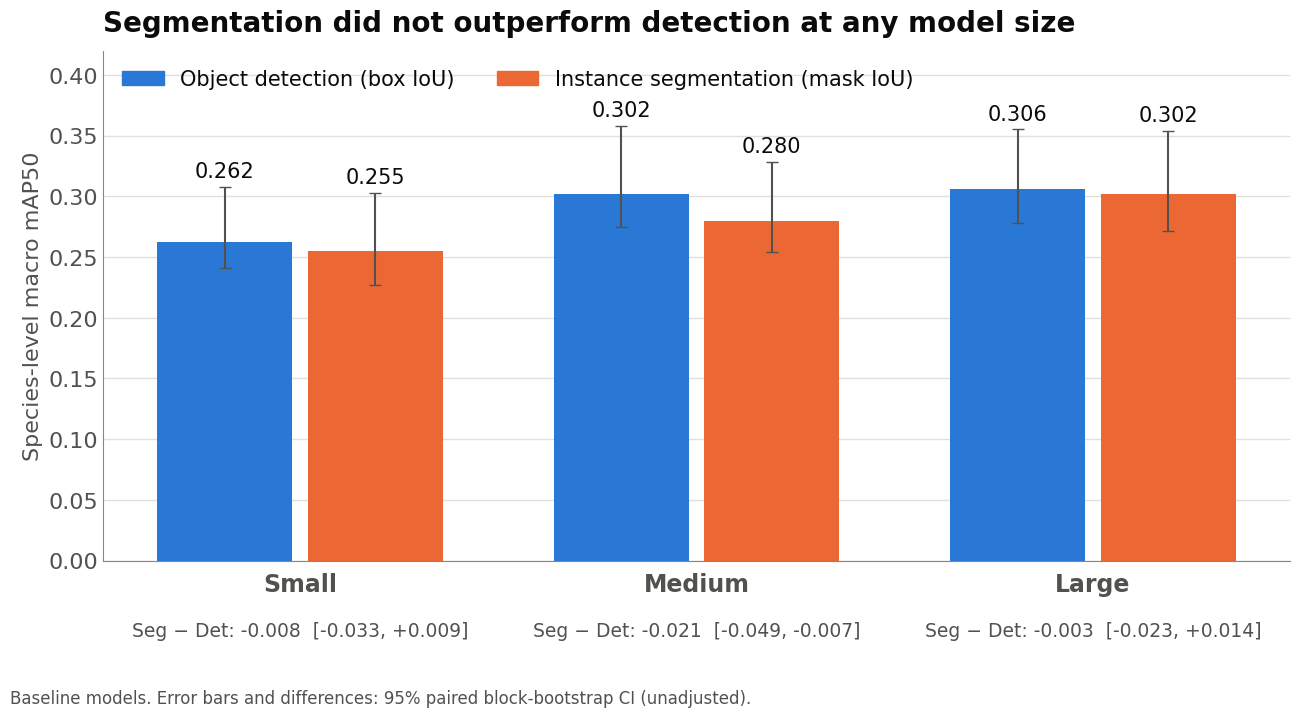

In [6]:
fig, ax = plt.subplots(figsize=FS)
x = np.arange(3); w = 0.34
for j, s in enumerate('sml'):
    for dx, task, col in [(-w / 2 - 0.02, 'detect', T['blue']), (w / 2 + 0.02, 'segment', T['orange'])]:
        m = f'{task}_{s}'; e = MACRO[m][0]
        ax.bar(j + dx, e, w, color=col)
        ax.errorbar(j + dx, e, yerr=err(MACRO, m), fmt='none', ecolor=T['ink2'], elinewidth=1.5, capsize=4)
        ax.text(j + dx, MACRO[m][2] + 0.008, f'{e:.3f}', ha='center', fontsize=15, color=T['ink'])
    dd = SEG_MINUS_DET[s]
    ax.text(j, -0.05, f'Seg − Det: {dd[0]:+.3f}  [{dd[1]:+.3f}, {dd[2]:+.3f}]', ha='center', va='top',
            fontsize=13.5, color=T['ink2'])
ax.set_xticks(x); ax.set_xticklabels(['Small', 'Medium', 'Large'], fontsize=17, fontweight='bold')
ax.tick_params(axis='x', pad=8); ax.set_ylim(0, 0.42); ax.set_ylabel('Species-level macro mAP50'); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=T['blue']), plt.Rectangle((0, 0), 1, 1, color=T['orange'])],
          labels=['Object detection (box IoU)', 'Instance segmentation (mask IoU)'], loc='upper left', ncol=2)
ax.set_title('Segmentation did not outperform detection at any model size')
fig.text(0.01, 0.01, 'Baseline models. Error bars and differences: 95% paired block-bootstrap CI (unadjusted).',
         fontsize=12, color=T['ink2'])
fig.subplots_adjust(left=0.08, right=0.97, top=0.88, bottom=0.2); save(fig, 'rq1_fig3_detection_vs_segmentation')

## Numbers for the script
Quick check of the values quoted in the speech.

In [7]:
print('Any-fish AP50 range: %.3f - %.3f' % (min(v[0] for v in ANYFISH.values()), max(v[0] for v in ANYFISH.values())))
print('Macro mAP50 range:   %.3f - %.3f' % (min(v[0] for v in MACRO.values()), max(v[0] for v in MACRO.values())))
for (t, a, b), d in SIZE_STEP.items():
    print(f'{t:8s} {a.upper()} -> {b.upper()}: {d[0]:+.3f}  CI [{d[1]:+.3f}, {d[2]:+.3f}]')
for s, d in SEG_MINUS_DET.items():
    print(f'seg - det ({s.upper()}): {d[0]:+.3f}  CI [{d[1]:+.3f}, {d[2]:+.3f}]')

Any-fish AP50 range: 0.670 - 0.694
Macro mAP50 range:   0.255 - 0.306
detect   S -> M: +0.039  CI [+0.019, +0.064]
detect   M -> L: +0.004  CI [-0.019, +0.020]
segment  S -> M: +0.025  CI [+0.008, +0.043]
segment  M -> L: +0.022  CI [+0.002, +0.041]
seg - det (S): -0.008  CI [-0.033, +0.009]
seg - det (M): -0.021  CI [-0.049, -0.007]
seg - det (L): -0.003  CI [-0.023, +0.014]
